In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults, sa_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot as sp


In [2]:
MU_B  = 5.788381806e-5# eV/T
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.01
n_max = 0.99
n_count = 40

# Magnetic field values
Ha_min = -1
Ha_max = 2
Ha_count = 1

# Beta values

beta_min =0
beta_max = 0
beta_count = 1

distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
# n  = np.array([0.5, 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
# H_a = np.array([0.0], dtype=np.float64) # NH
H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
H_a = np.concat([np.array([0.0]), H_a])

In [4]:
# n =np.array([0.01] + [0.025 + 0.025 * x for x in range(39)] + [0.99])
# beta= list(np.logspace(-2,3,61))
# beta.append(0.2)
# beta.append(np.inf)
# beta = np.sort(beta)
# beta = np.round(beta, 4)

In [5]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=1.4,
    initial_step=10.0,  
    max_expands=64,
    max_iters=500      
)
native_opts= py_opts.to_qss()

In [ ]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])
    mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

else:
    mu_df = chemical_potential(
        distros=distros,
        n_vals=n,
        beta_vals=beta,
        H_a_vals=H_a,
        N=N,
        E=e_k,
        solver_opts=native_opts,
        x0=2.0,
        a0=-5.0,
        b0=5.0,
    )
    k_BT = 1/beta
    mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged  residual
distro n        k_BT H_a                                           
FD     0.010000 1.0  0.0 -6.191736         250       True  0.000903
       0.035128 1.0  0.0 -4.830388         250       True  0.005411
       0.060256 1.0  0.0 -4.440690         250       True  0.002093
       0.085385 1.0  0.0 -3.949314         250       True  0.004840
       0.110513 1.0  0.0 -3.590046         250       True  0.012056
...                            ...         ...        ...       ...
SSL    0.889487 1.0  0.1  2.255583         250       True  0.008640
       0.914615 1.0  0.1  2.493163         250       True  0.000459
       0.939744 1.0  0.1  2.801256         250       True  0.006074
       0.964872 1.0  0.1  2.801256         250       True  0.031202
       0.990000 1.0  0.1  6.050569         250       True  0.006837

[400 rows x 4 columns]

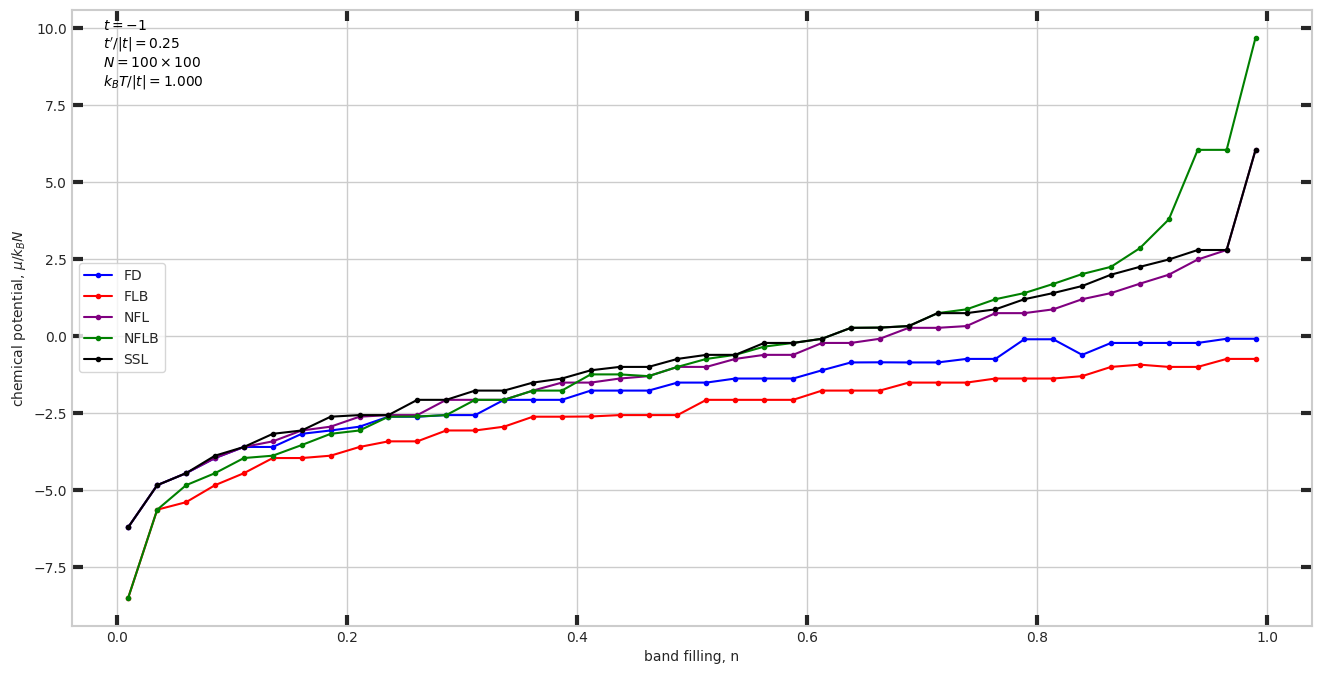

In [8]:
# Select a magnetic field to plot
H_a_plot = H_a[0]
beta_plot = beta

# Plotimport scientific_plot as sp
sp.plot_result_n(
    results=mu_df,
    n=n,
    betas=beta_plot,
    y_label=r"chemical potential, $\mu / k_B N$",
    distros=distros,
    H_a=H_a_plot,
    y_col="mu",  # Specify the column to plot
    legend_position="center left",
    figsize=(16, 8),
    cols=1 # Adjust columns for layout
)
plt.show()

<Figure size 640x480 with 0 Axes>

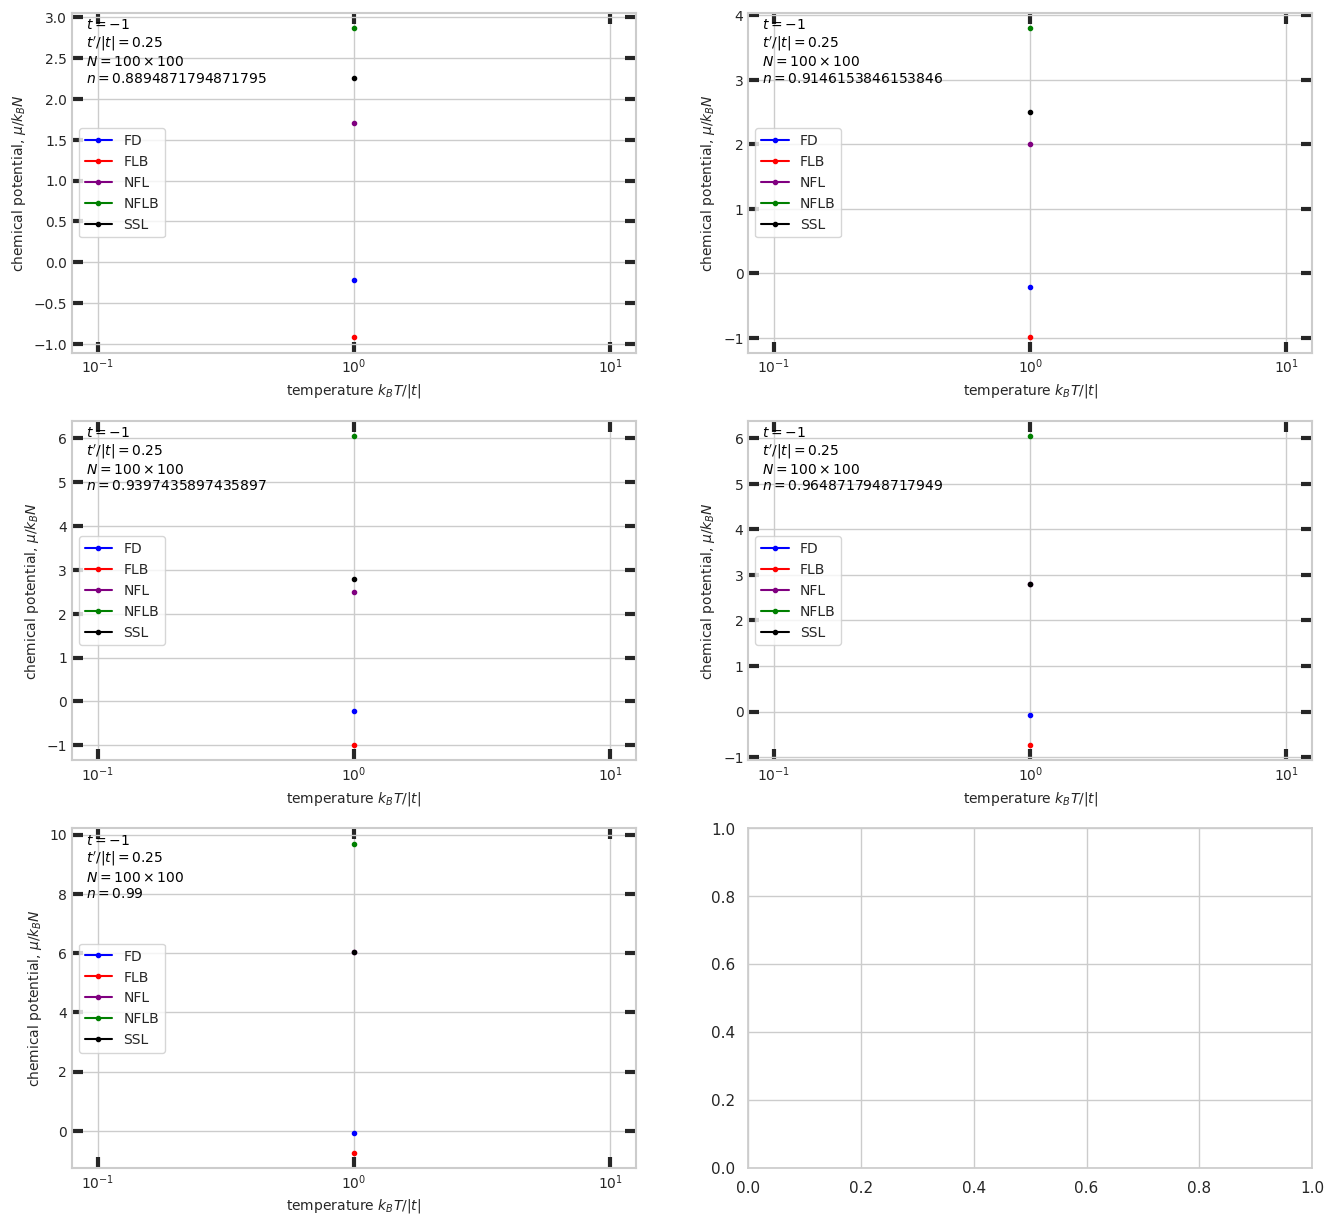

In [9]:
n_plot = n[-5:]
H_a_plot = H_a[0]

# Plotimport scientific_plot as sp
sp.plot_results_temperature(
    results=mu_df,
    n=n_plot,
    betas=beta,
    y_label=r"chemical potential, $\mu / k_B N$",
    distros=distros,
    H_a=H_a_plot,
    y_col="mu",  # Specify the column to plot
    legend_position="center left",
    figsize=(8, 5),
    cols=2 # Adjust columns for layout
)
plt.show()

<Figure size 640x480 with 0 Axes>

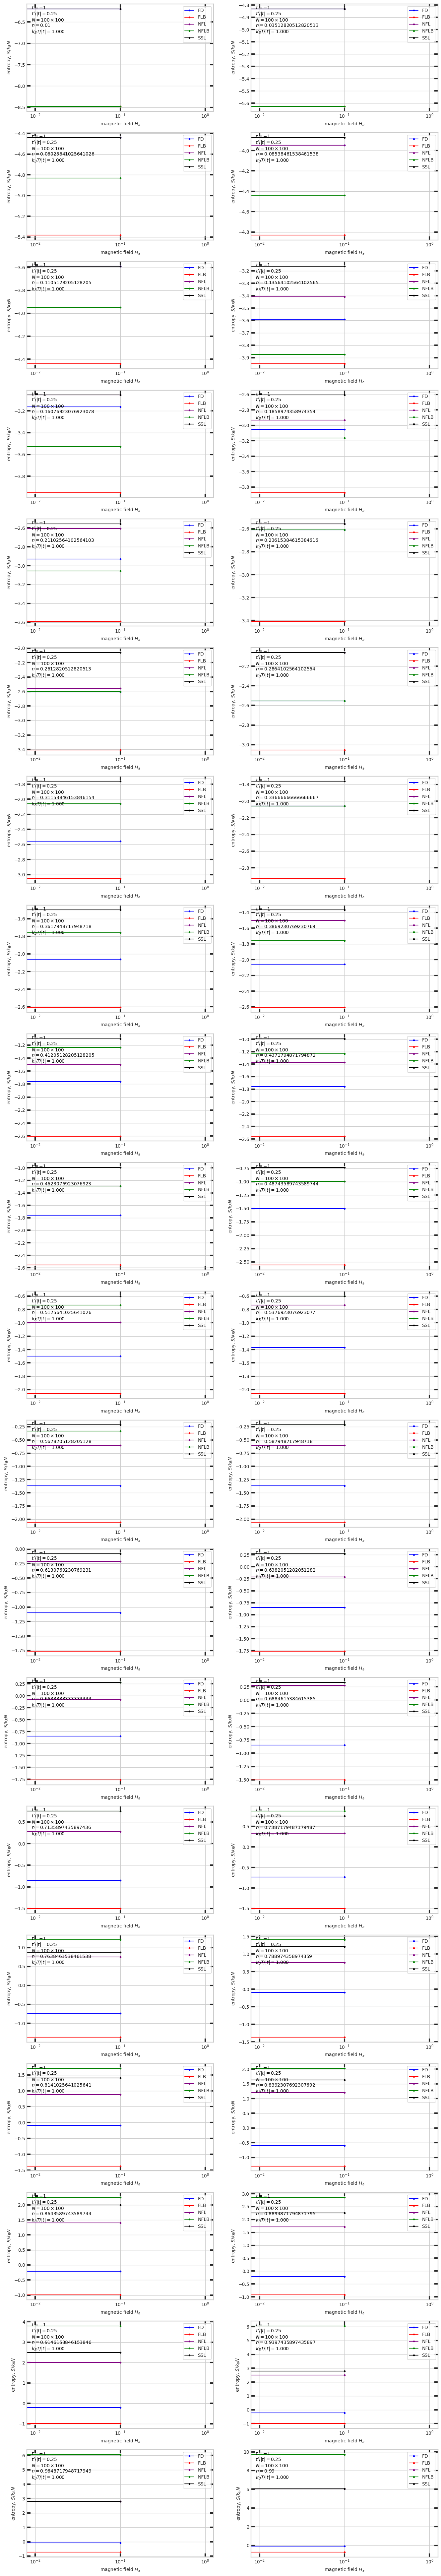

In [10]:
n_plot = n
beta_plot = beta[0]
sp.plot_results_Ha(
    results=mu_df,
    n=n_plot,          # List of n values to create subplots for
    beta=beta[-1],     # Fixed beta value
    y_label=r"entropy, $S / k_B N$",
    distros=distros,
    y_col="mu",
    legend_position="upper right",
    figsize=(8, 5),
    cols=2,
    # ylims=(-200, -60)
)
plt.show()

In [11]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
n_rows = [n[0], n[len(n)//2]] 
sp.plot_3d_results_interactive(
    results=mu_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a[:2],     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="mu",          # or "entropy" if you have calculated it
    distros=distros,
    # figsize=(15, 10)
)
plt.show()